# Vectors and Spaces - Theory & Implementations

This notebook follows the same chapter path as `notes.md`, but in the order that is easiest to learn by doing:

1. Concrete vectors in `R^n`
2. Linear combinations, span, independence, basis, and dimension
3. Norms, inner products, orthogonality, and projections
4. Affine/convex geometry and the probability simplex
5. High-dimensional geometry and random projection
6. Linear maps, rank-nullity, and the four fundamental subspaces
7. AI-specific spaces: embeddings, attention subspaces, LoRA, NTK
8. Regularization geometry: L1, L2, and spectral control

The notebook uses only `numpy` and optional `matplotlib`. It is intentionally code-first: the goal is to make the linear algebra feel operational.

Primary references behind the chapter: Axler, Vershynin, Mikolov et al. (2013), Vaswani et al. (2017), Ethayarajh (2019), Hu et al. (2022), Jacot et al. (2018), Miyato et al. (2018), and Amari (1998).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


In [2]:
import numpy as np
import numpy.linalg as la
import scipy.linalg as sla
from scipy import stats

COLORS = {
    "primary": "#0077BB",
    "secondary": "#EE7733",
    "tertiary": "#009988",
    "error": "#CC3311",
    "neutral": "#555555",
    "highlight": "#EE3377",
}
HAS_MPL = True
np.set_printoptions(precision=8, suppress=True)
np.random.seed(42)

def header(title):
    print("\n" + "=" * len(title))
    print(title)
    print("=" * len(title))

def check_true(name, cond):
    ok = bool(cond)
    print(f"{'PASS' if ok else 'FAIL'} - {name}")
    return ok

def check_close(name, got, expected, tol=1e-8):
    ok = np.allclose(got, expected, atol=tol, rtol=tol)
    print(f"{'PASS' if ok else 'FAIL'} - {name}: got {got}, expected {expected}")
    return ok

def check(name, got, expected, tol=1e-8):
    return check_close(name, got, expected, tol=tol)

def softmax(z, axis=-1, tau=1.0):
    z = np.asarray(z, dtype=float) / float(tau)
    z = z - np.max(z, axis=axis, keepdims=True)
    e = np.exp(z)
    return e / np.sum(e, axis=axis, keepdims=True)

def cosine_similarity(a, b):
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    return float(a @ b / (la.norm(a) * la.norm(b) + 1e-12))

def numerical_rank(A, tol=1e-10):
    return int(np.sum(la.svd(A, compute_uv=False) > tol))

def orthonormal_basis(A, tol=1e-10):
    Q, R = la.qr(A)
    keep = np.abs(np.diag(R)) > tol
    return Q[:, keep]

def null_space(A, tol=1e-10):
    U, S, Vt = la.svd(A)
    return Vt[S.size:,:].T if S.size < Vt.shape[0] else Vt[S <= tol,:].T



# Compatibility helpers used by the Chapter 02 theory and exercise cells.
def null_space(A, tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, S, Vt = la.svd(A, full_matrices=True)
    rank = int(np.sum(S > tol))
    return Vt[rank:].T

svd_null_space = null_space

def gram_schmidt(vectors, tol=1e-10):
    A = np.asarray(vectors, dtype=float)
    if A.ndim == 1:
        A = A.reshape(1, -1)
    basis = []
    for v in A:
        w = v.astype(float).copy()
        for q in basis:
            w = w - np.dot(w, q) * q
        norm = la.norm(w)
        if norm > tol:
            basis.append(w / norm)
    return np.array(basis)

def projection_matrix_from_columns(A, tol=1e-10):
    Q = orthonormal_basis(np.asarray(A, dtype=float), tol=tol)
    return Q @ Q.T


def random_unit_vectors(n, d):
    X = np.random.randn(n, d)
    return X / np.maximum(la.norm(X, axis=1, keepdims=True), 1e-12)

def pairwise_distances(X):
    X = np.asarray(X, dtype=float)
    diff = X[:, None, :] - X[None, :, :]
    return la.norm(diff, axis=-1)


def normalize(x, axis=None, tol=1e-12):
    x = np.asarray(x, dtype=float)
    norm = la.norm(x, axis=axis, keepdims=True)
    return x / np.maximum(norm, tol)

def frobenius_inner(A, B):
    return float(np.sum(np.asarray(A, dtype=float) * np.asarray(B, dtype=float)))

def outer_sum_product(A, B):
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    return sum(np.outer(A[:, k], B[k, :]) for k in range(A.shape[1]))

def softmax_rows(X):
    return softmax(X, axis=1)

def col_space(A, tol=1e-10):
    return orthonormal_basis(np.asarray(A, dtype=float), tol=tol)

def row_space(A, tol=1e-10):
    return orthonormal_basis(np.asarray(A, dtype=float).T, tol=tol).T

def rref(A, tol=1e-10):
    R = np.array(A, dtype=float, copy=True)
    m, n = R.shape
    pivots = []
    row = 0
    for col in range(n):
        pivot = row + int(np.argmax(np.abs(R[row:, col]))) if row < m else row
        if row >= m or abs(R[pivot, col]) <= tol:
            continue
        if pivot != row:
            R[[row, pivot]] = R[[pivot, row]]
        R[row] = R[row] / R[row, col]
        for r in range(m):
            if r != row:
                R[r] = R[r] - R[r, col] * R[row]
        pivots.append(col)
        row += 1
        if row == m:
            break
    R[np.abs(R) < tol] = 0.0
    return R, pivots

def nullspace_basis(A, tol=1e-10):
    A = np.asarray(A, dtype=float)
    U, S, Vt = la.svd(A, full_matrices=True)
    rank = int(np.sum(S > tol))
    return Vt[rank:].T, rank

print("Chapter helper setup complete.")



Chapter helper setup complete.


---
## 1. Concrete Vectors in R^n

Start concrete. If vector addition, scaling, linear combinations, and angles are not automatic yet, abstract vector spaces will feel harder than they need to.

We begin with the standard Euclidean setting and then reuse the same algebra everywhere else.

In [3]:
# === 1.1 Basic vector operations ===
u = np.array([1.0, 2.0, -1.0])
v = np.array([3.0, 0.0, 1.0])
alpha = -2.5

print("u =", u)
print("v =", v)
print("u + v =", u + v)
print("alpha * u =", alpha * u)
print("u dot v =", np.dot(u, v))
print("||u||_2 =", np.linalg.norm(u))
print("||v||_2 =", np.linalg.norm(v))
print("cos(u, v) =", cosine_similarity(u, v))

angle_radians = np.arccos(np.clip(cosine_similarity(u, v), -1.0, 1.0))
angle_degrees = np.degrees(angle_radians)
print("angle(u, v) in degrees =", angle_degrees)

# Linear combination
w = 2 * u - 0.5 * v
print("w = 2u - 0.5v =", w)

u = [ 1.  2. -1.]
v = [3. 0. 1.]
u + v = [4. 2. 0.]
alpha * u = [-2.5 -5.   2.5]
u dot v = 2.0
||u||_2 = 2.449489742783178
||v||_2 = 3.1622776601683795
cos(u, v) = 0.2581988897471278
angle(u, v) in degrees = 75.03678256669485
w = 2u - 0.5v = [ 0.5  4.  -2.5]


In [4]:
# === 1.2 Span, linear independence, and abstract examples ===
independent = np.column_stack([
    np.array([1.0, 0.0, 0.0]),
    np.array([0.0, 1.0, 0.0]),
    np.array([0.0, 0.0, 1.0])
])

dependent = np.column_stack([
    np.array([1.0, 2.0]),
    np.array([2.0, 4.0])
])

print("rank(independent columns) =", np.linalg.matrix_rank(independent))
print("rank(dependent columns) =", np.linalg.matrix_rank(dependent))

target = np.array([7.0, 4.0])
standard_basis = np.column_stack([
    np.array([1.0, 0.0]),
    np.array([0.0, 1.0])
])
coords, *_ = np.linalg.lstsq(standard_basis, target, rcond=None)
print("coordinates of", target, "in the standard basis =", coords)

# Polynomials also form a vector space if we represent them by coefficients.
# p(x) = 1 + 2x - x^2  -> [1, 2, -1]
# q(x) = 3 - x + 4x^2 -> [3, -1, 4]
p = np.array([1.0, 2.0, -1.0])
q = np.array([3.0, -1.0, 4.0])
print("p + q coefficients =", p + q)
print("3p coefficients =", 3 * p)

# Function spaces also behave linearly under pointwise operations.
x = np.linspace(0.0, 1.0, 5)
f = x**2
g = np.sin(np.pi * x)
print("(f + g)(x) sampled =", f + g)
print("(2f - g)(x) sampled =", 2 * f - g)

rank(independent columns) = 3
rank(dependent columns) = 1
coordinates of [7. 4.] in the standard basis = [7. 4.]
p + q coefficients = [4. 1. 3.]
3p coefficients = [ 3.  6. -3.]
(f + g)(x) sampled = [0.         0.76960678 1.25       1.26960678 1.        ]
(2f - g)(x) sampled = [ 0.         -0.58210678 -0.5         0.41789322  2.        ]


---
## 2. Basis, Coordinates, and Dimension

A basis is the minimal non-redundant coordinate system for a space: independent enough to avoid redundancy, rich enough to span everything.

Learning move: compute coordinates in a non-standard basis and reconstruct the original vector.

In [5]:
# === 2.1 Coordinates in a non-standard basis ===
B = np.column_stack([
    np.array([1.0, 1.0]),
    np.array([1.0, -1.0])
])
x = np.array([4.0, 2.0])

coords_in_B = np.linalg.solve(B, x)
reconstructed = B @ coords_in_B

print("basis matrix B =\n", B)
print("vector x =", x)
print("[x]_B =", coords_in_B)
print("reconstructed from basis coordinates =", reconstructed)

# Change of basis idea: the vector is unchanged, only coordinates change.
standard_coords = x
print("[x]_standard =", standard_coords)
print("dimension of the space =", B.shape[0])

basis matrix B =
 [[ 1.  1.]
 [ 1. -1.]]
vector x = [4. 2.]
[x]_B = [3. 1.]
reconstructed from basis coordinates = [4. 2.]
[x]_standard = [4. 2.]
dimension of the space = 2


---
## 3. Norms, Metrics, and Size

Norms measure size. Metrics measure distance. In finite dimensions all norms are equivalent in the topological sense, but they induce very different optimization geometry.

For AI, this is exactly why L1, L2, and L-infinity constraints lead to different behavior.

In [6]:
# === 3.1 Vector and matrix norms ===
v = np.array([3.0, -4.0, 0.0, 1.0])

l1 = np.linalg.norm(v, 1)
l2 = np.linalg.norm(v, 2)
linf = np.linalg.norm(v, np.inf)

print("v =", v)
print("||v||_1 =", l1)
print("||v||_2 =", l2)
print("||v||_inf =", linf)
print("Inequalities hold:", linf <= l2 <= l1)

M = np.array([[2.0, 1.0], [1.0, 2.0]])
singular_values = np.linalg.svd(M, compute_uv=False)
fro = np.linalg.norm(M, 'fro')
spec = singular_values[0]

print("\nM =\n", M)
print("singular values =", singular_values)
print("||M||_F =", fro)
print("||M||_2 =", spec)

# Random check of norm inequalities on several samples.
ok = True
for _ in range(100):
    z = np.random.randn(16)
    ok &= np.linalg.norm(z, np.inf) <= np.linalg.norm(z, 2) + 1e-12
    ok &= np.linalg.norm(z, 2) <= np.linalg.norm(z, 1) + 1e-12
print("Random finite-dimensional norm checks passed:", ok)

v = [ 3. -4.  0.  1.]
||v||_1 = 8.0
||v||_2 = 5.0990195135927845
||v||_inf = 4.0
Inequalities hold: True

M =
 [[2. 1.]
 [1. 2.]]
singular values = [3. 1.]
||M||_F = 3.1622776601683795
||M||_2 = 2.9999999999999996
Random finite-dimensional norm checks passed: True


---
## 4. Inner Products, Orthogonality, and Projection

Once a space has an inner product, it has geometry: angle, orthogonality, and best approximation.

This is the section to internalize if you want attention, least squares, and signal decomposition to feel natural.

In [7]:
# === 4.1 Gram-Schmidt and orthonormalization ===
vectors = np.array([
    [1.0, 1.0, 0.0],
    [1.0, 0.0, 1.0],
    [0.0, 1.0, 1.0]
])
Q = gram_schmidt(vectors)

print("orthonormal basis from Gram-Schmidt =\n", Q)
print("Q Q^T =\n", Q @ Q.T)

# === 4.2 Projection onto a line ===
u = np.array([1.0, 2.0, 2.0])
P_line = np.outer(u, u) / np.dot(u, u)
x = np.array([3.0, -1.0, 4.0])
proj_x = P_line @ x
resid_x = x - proj_x

print("\nprojection matrix onto span(u) =\n", P_line)
print("P^2 == P:", np.allclose(P_line @ P_line, P_line))
print("P^T == P:", np.allclose(P_line.T, P_line))
print("projection of x onto span(u) =", proj_x)
print("residual =", resid_x)
print("residual orthogonal to u:", np.allclose(np.dot(resid_x, u), 0.0))

# === 4.3 Projection onto a column space and least squares ===
A = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0]
])
P_A = projection_matrix_from_columns(A)
b = np.array([2.0, 1.0, 4.0])
proj_b = P_A @ b
resid_b = b - proj_b
x_star, *_ = np.linalg.lstsq(A, b, rcond=None)

print("\nprojection onto col(A) =\n", P_A)
print("rank(P_A) =", np.linalg.matrix_rank(P_A))
print("projected b =", proj_b)
print("least-squares coefficients x* =", x_star)
print("A x* =", A @ x_star)
print("residual orthogonal to columns of A:", np.allclose(A.T @ resid_b, 0.0))

orthonormal basis from Gram-Schmidt =
 [[ 0.70710678  0.70710678  0.        ]
 [ 0.40824829 -0.40824829  0.81649658]
 [-0.57735027  0.57735027  0.57735027]]
Q Q^T =
 [[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]

projection matrix onto span(u) =
 [[0.11111111 0.22222222 0.22222222]
 [0.22222222 0.44444444 0.44444444]
 [0.22222222 0.44444444 0.44444444]]
P^2 == P: True
P^T == P: True
projection of x onto span(u) = [1. 2. 2.]
residual = [ 2. -3.  2.]
residual orthogonal to u: True

projection onto col(A) =
 [[ 0.66666667 -0.33333333  0.33333333]
 [-0.33333333  0.66666667  0.33333333]
 [ 0.33333333  0.33333333  0.66666667]]
rank(P_A) = 2
projected b = [2.33333333 1.33333333 3.66666667]
least-squares coefficients x* = [2.33333333 1.33333333]
A x* = [2.33333333 1.33333333 3.66666667]
residual orthogonal to columns of A: True


---
## 5. Affine Spaces, Convexity, and the Probability Simplex

Subspaces pass through the origin. Affine spaces are translated subspaces. Convex sets contain line segments. The probability simplex is the most important convex set in language modeling.

Attention outputs live in convex hulls because attention weights are nonnegative and sum to one.

In [8]:
# === 5.1 Convex combinations and simplex geometry ===
values = np.array([
    [2.0, 0.0],
    [0.0, 2.0],
    [1.0, 1.0]
])
logits = np.array([2.5, 1.0, -0.5])

for tau in [0.2, 1.0, 5.0]:
    weights = softmax(logits, tau=tau)
    output = weights @ values
    print(f"tau={tau:>3}: weights={weights}, output={output}, sum(weights)={weights.sum():.4f}")

# Simplex points stay in the simplex under convex combinations.
p = np.array([0.7, 0.2, 0.1])
q = np.array([0.1, 0.3, 0.6])
lam = 0.35
r = lam * p + (1 - lam) * q
print("\np =", p)
print("q =", q)
print("convex combination r =", r)
print("r is in simplex:", np.all(r >= 0) and np.isclose(r.sum(), 1.0))

# Affine example: x + y + z = 1
a = np.array([1.0, 0.0, 0.0])
b = np.array([0.0, 1.0, 0.0])
mid = 0.5 * a + 0.5 * b
print("\naffine slice example point:", mid, "sum =", mid.sum())

tau=0.2: weights=[0.99944692 0.00055278 0.00000031], output=[1.99889414 0.00110586], sum(weights)=1.0000
tau=1.0: weights=[0.78559703 0.17529039 0.03911257], output=[1.61030664 0.38969336], sum(weights)=1.0000
tau=5.0: weights=[0.43675182 0.3235537  0.23969448], output=[1.11319811 0.88680189], sum(weights)=1.0000

p = [0.7 0.2 0.1]
q = [0.1 0.3 0.6]
convex combination r = [0.31  0.265 0.425]
r is in simplex: True

affine slice example point: [0.5 0.5 0. ] sum = 1.0


---
## 6. High-Dimensional Geometry

This is where low-dimensional intuition breaks.

Random high-dimensional vectors are usually nearly orthogonal. Distances concentrate. Random projections can preserve geometry much better than intuition suggests. These facts are central to embedding spaces and approximate nearest-neighbor retrieval.

d=   2 | mean cosine=-0.0009 | std cosine= 0.7066
d=  10 | mean cosine=-0.0015 | std cosine= 0.3166
d= 100 | mean cosine=-0.0001 | std cosine= 0.1001
d=1000 | mean cosine= 0.0001 | std cosine= 0.0315

Random projection distance preservation summary
median relative error = 0.051900102052383504
90th percentile relative error = 0.13668303498995382
max relative error = 0.2845646927314718


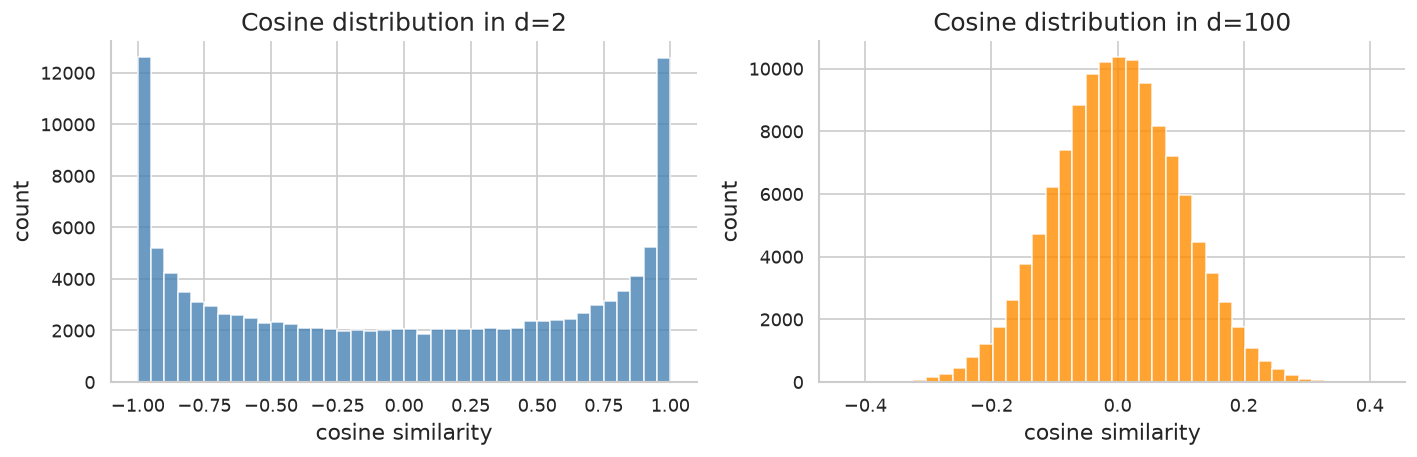

In [9]:
# === 6.1 Random vectors become nearly orthogonal ===
for d in [2, 10, 100, 1000]:
    X = random_unit_vectors(400, d)
    G = X @ X.T
    upper = G[np.triu_indices_from(G, k=1)]
    print(f"d={d:>4} | mean cosine={upper.mean(): .4f} | std cosine={upper.std(): .4f}")

# === 6.2 Johnson-Lindenstrauss style random projection ===
n_points = 120
d_original = 500
d_projected = 80

X = np.random.randn(n_points, d_original)
R = np.random.randn(d_original, d_projected) / np.sqrt(d_projected)
Y = X @ R

D_X = pairwise_distances(X[:40])
D_Y = pairwise_distances(Y[:40])
mask = np.triu(np.ones_like(D_X, dtype=bool), k=1)
relative_error = np.abs(D_Y[mask] - D_X[mask]) / np.maximum(D_X[mask], 1e-12)

print("\nRandom projection distance preservation summary")
print("median relative error =", np.median(relative_error))
print("90th percentile relative error =", np.percentile(relative_error, 90))
print("max relative error =", np.max(relative_error))

if HAS_MPL:
    X2 = random_unit_vectors(500, 2)
    X100 = random_unit_vectors(500, 100)
    c2 = (X2 @ X2.T)[np.triu_indices(500, 1)]
    c100 = (X100 @ X100.T)[np.triu_indices(500, 1)]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(c2, bins=40, color='steelblue', alpha=0.8)
    axes[0].set_title('Cosine distribution in d=2')
    axes[1].hist(c100, bins=40, color='darkorange', alpha=0.8)
    axes[1].set_title('Cosine distribution in d=100')
    for ax in axes:
        ax.set_xlabel('cosine similarity')
        ax.set_ylabel('count')
    plt.tight_layout()
    plt.show()

---
## 7. Linear Maps, Rank-Nullity, and the Four Fundamental Subspaces

A linear map is a geometry-preserving algebraic rule. The kernel tells you what is lost. The image tells you what can be produced. Rank-nullity counts both exactly.

This section is the cleanest bridge between vectors and matrices.

In [10]:
# === 7.1 Null space and row space are orthogonal complements ===
# (Four fundamental subspaces — canonical treatment in 06-Vector-Spaces-Subspaces)

import numpy as np

A = np.array([
    [1.0, 2.0, 3.0],
    [2.0, 4.0, 6.0],   # row 2 = 2 * row 1  (rank-deficient)
    [1.0, 1.0, 2.0]
])

# Rank and nullity
rank    = np.linalg.matrix_rank(A)
nullity = A.shape[1] - rank
print(f'Shape: {A.shape},  rank = {rank},  nullity = {nullity}')
print(f'rank + nullity = {rank} + {nullity} = {rank + nullity} = n  (rank-nullity theorem)')

# A vector in the null space
_, _, Vt = np.linalg.svd(A, full_matrices=True)
null_vec = Vt[-1]   # last right singular vector spans null(A)
print(f'\nnull_vec = {null_vec.round(4)}')
print(f'A @ null_vec = {(A @ null_vec).round(10)}  (should be ~0)')

# A vector in the row space
row_vec = Vt[0]     # first right singular vector spans row(A)
print(f'row_vec  = {row_vec.round(4)}')

# Orthogonality: null(A) perp row(A)
dot = float(null_vec @ row_vec)
print(f'\nnull_vec . row_vec = {dot:.2e}  (numerically zero — they are orthogonal)')

# Forward reference
print('\n-> Full four-subspace theory (col, row, null, left-null) with bases and')
print('   dimensional identities: 06-Vector-Spaces-Subspaces Section 7.')


Shape: (3, 3),  rank = 2,  nullity = 1
rank + nullity = 2 + 1 = 3 = n  (rank-nullity theorem)

null_vec = [-0.5774 -0.5774  0.5774]
A @ null_vec = [-0. -0. -0.]  (should be ~0)
row_vec  = [-0.2786 -0.5254 -0.804 ]

null_vec . row_vec = 2.05e-17  (numerically zero — they are orthogonal)

-> Full four-subspace theory (col, row, null, left-null) with bases and
   dimensional identities: 06-Vector-Spaces-Subspaces Section 7.


---
## 8. AI-Specific Spaces: Embeddings, Attention, Low Rank, and NTK

This is the point of the chapter from an AI perspective.

- Embeddings are vectors in learned spaces.
- Attention heads operate in projected subspaces.
- LoRA uses low-rank updates in matrix space.
- NTK treats training through inner products of parameter gradients.

The examples below are deliberately small, but the geometry is the same as in large models.

In [11]:
# === 8.1 Synthetic embedding geometry ===
tokens = ["king", "queen", "man", "woman", "apple"]
E = np.array([
    [0.8, 0.9, 0.2, 0.1],
    [0.8, 0.9, -0.2, 0.1],
    [0.7, 0.8, 0.4, 0.1],
    [0.7, 0.8, -0.4, 0.1],
    [-0.3, 0.2, 0.0, 0.9]
], dtype=float)

def nearest(vec, names, matrix):
    sims = [cosine_similarity(vec, row) for row in matrix]
    order = np.argsort(sims)[::-1]
    return [(names[i], float(sims[i])) for i in order[:3]]

analogy = E[0] - E[2] + E[3]  # king - man + woman
print("Nearest tokens to king - man + woman:")
for name, sim in nearest(analogy, tokens, E):
    print(f"  {name:>5} | cosine={sim:.4f}")

# === 8.2 Attention interaction rank is bounded by head dimension ===
d = 32
d_k = 6
W_Q = np.random.randn(d, d_k)
W_K = np.random.randn(d, d_k)
interaction = W_Q @ W_K.T
print("\nrank(W_Q W_K^T) =", np.linalg.matrix_rank(interaction))
print("head dimension bound d_k =", d_k)

# === 8.3 LoRA-style low-rank update ===
r = 3
B = np.random.randn(d, r)
A_small = np.random.randn(r, d)
delta_W = B @ A_small
print("rank(delta_W) <=", r, "and observed rank =", np.linalg.matrix_rank(delta_W))

# === 8.4 NTK for a linear model ===
# For f_theta(x) = theta^T x, grad_theta f(x) = x, so NTK(x, x') = x^T x'.
X = np.array([
    [-1.0, 0.0],
    [-0.2, 1.0],
    [0.4, 1.2],
    [1.1, -0.3]
])
K = X @ X.T
print("\nLinear-model NTK Gram matrix =\n", K)

# === 8.5 Softmax geometry in vocabulary space ===
logits = np.array([4.0, 1.5, 0.2, -0.5])
for tau in [0.25, 1.0, 3.0]:
    p = softmax(logits, tau=tau)
    print(f"tau={tau:>4}: probs={p}, entropy={-np.sum(p * np.log(p + 1e-12)):.4f}")

Nearest tokens to king - man + woman:
  woman | cosine=0.9947
  queen | cosine=0.9563
   king | cosine=0.8110

rank(W_Q W_K^T) = 6
head dimension bound d_k = 6
rank(delta_W) <= 3 and observed rank = 3

Linear-model NTK Gram matrix =
 [[ 1.    0.2  -0.4  -1.1 ]
 [ 0.2   1.04  1.12 -0.52]
 [-0.4   1.12  1.6   0.08]
 [-1.1  -0.52  0.08  1.3 ]]
tau=0.25: probs=[0.99995434 0.0000454  0.00000025 0.00000002], entropy=0.0005
tau= 1.0: probs=[0.89640694 0.07358156 0.02005332 0.00995818], entropy=0.4143
tau= 3.0: probs=[0.51559743 0.22407772 0.14527952 0.11504534], entropy=1.2057


---
## 9. Regularization Geometry

L2 regularization shrinks smoothly toward the origin. L1 regularization prefers corners and therefore sparsity. Spectral normalization constrains the maximum stretch of a linear map.

This is best understood geometrically rather than heuristically.

gradient direction g = [0.94385836 0.33035042]
best point on unit L2 ball = [0.94385836 0.33035042]
best point on unit L1 ball = [1. 0.]
objective value on L2 ball = 1.0
objective value on L1 ball = 0.9438583563660174

W =
 [[2. 1.]
 [0. 1.]]
spectral norm of W = 2.2882456112707374


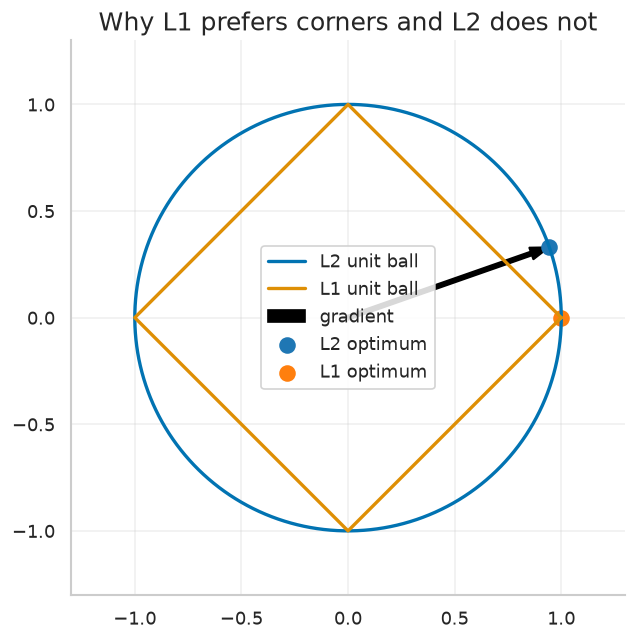

In [12]:
# === 9.1 L1 vs L2 geometry for a simple linear objective ===
g = np.array([1.0, 0.35])
g = normalize(g)

# On the unit L2 ball, the maximizer of g^T theta is g itself.
theta_l2 = g

# On the unit L1 ball in 2D, the maximizer lands on a corner aligned with the largest magnitude coordinate.
theta_l1 = np.array([1.0, 0.0]) if abs(g[0]) >= abs(g[1]) else np.array([0.0, 1.0])
theta_l1 *= np.sign(g[np.argmax(np.abs(g))])

print("gradient direction g =", g)
print("best point on unit L2 ball =", theta_l2)
print("best point on unit L1 ball =", theta_l1)
print("objective value on L2 ball =", float(g @ theta_l2))
print("objective value on L1 ball =", float(g @ theta_l1))

# Spectral norm as maximum stretch.
W = np.array([[2.0, 1.0], [0.0, 1.0]])
sigma_max = np.linalg.svd(W, compute_uv=False)[0]
print("\nW =\n", W)
print("spectral norm of W =", sigma_max)

if HAS_MPL:
    t = np.linspace(0, 2 * np.pi, 400)
    l2_x = np.cos(t)
    l2_y = np.sin(t)
    diamond = np.array([
        [1.0, 0.0],
        [0.0, 1.0],
        [-1.0, 0.0],
        [0.0, -1.0],
        [1.0, 0.0]
    ])

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(l2_x, l2_y, label='L2 unit ball', linewidth=2)
    ax.plot(diamond[:, 0], diamond[:, 1], label='L1 unit ball', linewidth=2)
    ax.arrow(0, 0, g[0], g[1], width=0.02, color='black', length_includes_head=True, label='gradient')
    ax.scatter(*theta_l2, color='tab:blue', s=80, label='L2 optimum')
    ax.scatter(*theta_l1, color='tab:orange', s=80, label='L1 optimum')
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_title('Why L1 prefers corners and L2 does not')
    plt.show()

## Appended Demo 1: Vector Algebra and the Triangle Inequality

Appended audit. Addition, scaling, and norms are checked as algebra, not just drawn: the parallelogram identity and triangle inequality must hold for every random pair.

In [13]:

import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt
import scipy.linalg as sla
np.random.seed(42)
WONG = ["#0077BB", "#EE7733", "#009988", "#CC3311", "#555555", "#EE3377"]
def check_true(name, cond):
    print(("PASS: " if bool(cond) else "FAIL: ") + name)
def check_close(name, a, b, tol):
    err = float(np.max(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))))
    print(("PASS: " if err <= tol else "FAIL: ") + f"{name} (max err {err:.2e}, tol {tol:.0e})")

rng = np.random.default_rng(42)
ok_tri = True; ok_par = True
for _ in range(200):
    x = rng.normal(size=5); y = rng.normal(size=5)
    ok_tri &= la.norm(x + y) <= la.norm(x) + la.norm(y) + 1e-12
    ok_par &= abs(la.norm(x+y)**2 + la.norm(x-y)**2 - 2*la.norm(x)**2 - 2*la.norm(y)**2) < 1e-9
check_true("triangle inequality on 200 random pairs in R^5", ok_tri)
check_true("parallelogram identity on 200 random pairs", ok_par)
print("vector algebra is the contract every later linear map must respect")

PASS: triangle inequality on 200 random pairs in R^5
PASS: parallelogram identity on 200 random pairs
vector algebra is the contract every later linear map must respect


## Appended Demo 2: Linear Combinations and Span

A span is all reachable linear combinations. In R^2 two non-parallel vectors span the plane; the plot shows a target reached as a combination, and the solver recovers the coefficients.

PASS: target reconstructed from u and v (max err 4.44e-16, tol 1e-12)


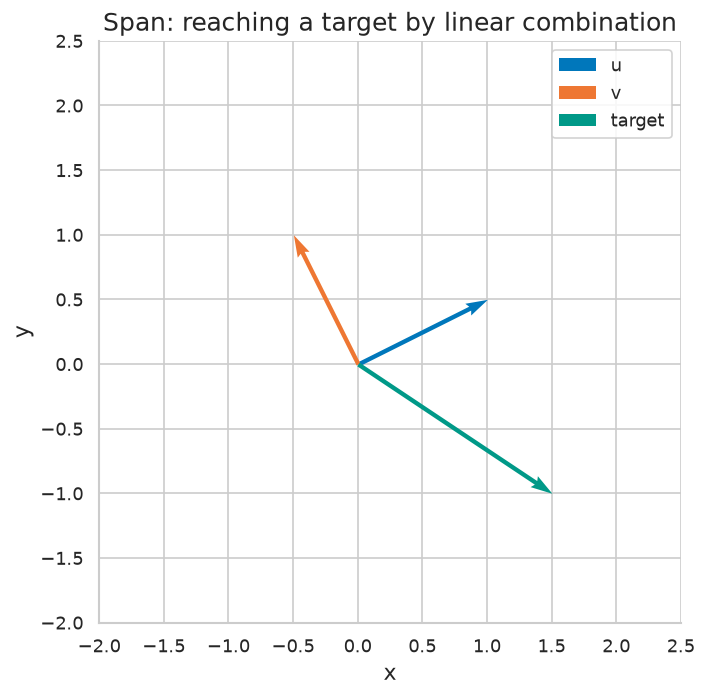

coefficients: [ 0.8 -1.4]


In [14]:

u = np.array([1.0, 0.5]); v = np.array([-0.5, 1.0]); target = np.array([1.5, -1.0])
coef, *_ = la.lstsq(np.column_stack([u, v]), target, rcond=None)
check_close("target reconstructed from u and v", coef @ np.array([u, v]), target, 1e-12)
fig, ax = plt.subplots()
ax.quiver(0, 0, u[0], u[1], angles='xy', scale_units='xy', scale=1, color=WONG[0], label='u')
ax.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1, color=WONG[1], label='v')
ax.quiver(0, 0, target[0], target[1], angles='xy', scale_units='xy', scale=1, color=WONG[2], label='target')
ax.set_xlim(-2, 2.5); ax.set_ylim(-2, 2.5); ax.set_title("Span: reaching a target by linear combination"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(); ax.set_aspect('equal')
plt.tight_layout(); plt.show()
print(f"coefficients: {coef}")

## Appended Demo 3: Linear Independence Is a Rank Test

Vectors are independent exactly when the matrix with those columns has full column rank. Dependence is not a vibe: a nonzero coefficient vector in the null space certifies it.

In [15]:

A = np.array([[1., 2.], [2., 4.], [0., 1.]])  # columns: second is not a multiple issue? rows as vectors below
vecs_dep = np.array([[1., 0.], [0., 1.], [1., 1.]])
check_true("three vectors in R^2 must be dependent (rank 2 < 3)", la.matrix_rank(vecs_dep.T) == 2)
B = np.array([[1., 2.], [3., 1.]])
check_true("two non-parallel vectors in R^2 are independent", la.matrix_rank(B) == 2 and abs(la.det(B)) > 1e-9)
print("independence = trivial null space of the column matrix")

PASS: three vectors in R^2 must be dependent (rank 2 < 3)
PASS: two non-parallel vectors in R^2 are independent
independence = trivial null space of the column matrix


## Appended Demo 4: Coordinates Depend on the Basis

The same geometric vector has different coordinates in different bases. Change of basis is a solve, and round-tripping through two bases must return the original coordinates.

In [16]:

B = np.array([[1., 1.], [1., -1.]])  # columns are basis vectors
x_geom = np.array([3., 1.])
coord_B = la.solve(B, x_geom)
check_close("coordinates in basis B reconstruct the vector", B @ coord_B, x_geom, 1e-12)
C = np.array([[2., 0.], [1., 1.]])
coord_C = la.solve(C, x_geom)
check_close("change B -> C preserves the geometric vector", C @ coord_C, B @ coord_B, 1e-12)
print(f"coords in B: {coord_B}; coords in C: {coord_C}; same vector, different numbers")

PASS: coordinates in basis B reconstruct the vector (max err 0.00e+00, tol 1e-12)
PASS: change B -> C preserves the geometric vector (max err 0.00e+00, tol 1e-12)
coords in B: [2. 1.]; coords in C: [ 1.5 -0.5]; same vector, different numbers


## Appended Demo 5: Dot Product, Angle, and Projection

Projection splits a vector into parallel and orthogonal parts. The residual being orthogonal to the direction is the defining check, and it is also the least-squares condition in embryo.

In [17]:

a = np.array([2., 1.]); b = np.array([1., 3.])
proj = (a @ b) / (b @ b) * b; resid = a - proj
check_true("projection residual is orthogonal to b", abs(resid @ b) < 1e-12)
cosang = (a @ b) / (la.norm(a) * la.norm(b))
check_true("cosine of angle lies in [-1, 1] and matches arccos geometry", -1 <= cosang <= 1 and abs(np.arccos(cosang) - np.arccos(np.clip(cosang,-1,1))) < 1e-15)
print(f"cos(angle) = {cosang:.4f}; proj = {proj}; residual = {resid}")

PASS: projection residual is orthogonal to b
PASS: cosine of angle lies in [-1, 1] and matches arccos geometry
cos(angle) = 0.7071; proj = [0.5 1.5]; residual = [ 1.5 -0.5]


## Appended Demo 6: Cauchy-Schwarz and Its Equality Case

Cauchy-Schwarz bounds every inner product by the product of norms, with equality only for parallel vectors. Random search should approach but never cross the bound.

In [18]:

rng = np.random.default_rng(42)
worst = 0.0
for _ in range(1000):
    x = rng.normal(size=8); y = rng.normal(size=8)
    worst = max(worst, abs(x @ y) / (la.norm(x) * la.norm(y)))
check_true("1000 random pairs respect |<x,y>| <= ||x|| ||y||", worst <= 1 + 1e-12)
x = np.array([1., 2., 3.]); y = 2.5 * x
check_true("equality holds for parallel vectors", abs(abs(x @ y) - la.norm(x) * la.norm(y)) < 1e-10)
print(f"largest random cosine magnitude seen: {worst:.4f} (< 1, as required)")

PASS: 1000 random pairs respect |<x,y>| <= ||x|| ||y||
PASS: equality holds for parallel vectors
largest random cosine magnitude seen: 0.9069 (< 1, as required)


## Appended Demo 7: Gram-Schmidt Builds an Orthonormal Basis

Gram-Schmidt subtracts projections onto earlier directions, then normalises. The output must satisfy Q^T Q = I and span the same subspace as the input.

In [19]:

A = np.array([[1., 1., 0.], [1., 0., 1.], [0., 1., 1.]])
qs = []
for j in range(A.shape[1]):
    w = A[:, j].astype(float).copy()
    for q in qs: w = w - (w @ q) * q
    qs.append(w / la.norm(w))
Q = np.column_stack(qs)
check_close("Gram-Schmidt output is orthonormal (Q^T Q = I)", Q.T @ Q, np.eye(3), 1e-12)
check_true("orthonormal basis spans the same (full) space", la.matrix_rank(np.column_stack([Q, A])) == 3)
print("orthonormalisation changes the basis, not the span")

PASS: Gram-Schmidt output is orthonormal (Q^T Q = I) (max err 2.22e-16, tol 1e-12)
PASS: orthonormal basis spans the same (full) space
orthonormalisation changes the basis, not the span


## Appended Demo 8: Subspaces Must Pass Through the Origin

A subspace contains zero and is closed under addition and scaling. A shifted line fails at the first test, which is why affine sets need separate treatment.

In [20]:

def in_span_set(x): return abs(x[1] - 2 * x[0]) < 1e-9          # line y=2x through origin
def in_shifted(x): return abs(x[1] - (2 * x[0] + 1)) < 1e-9      # shifted line y=2x+1
x = np.array([1., 2.]); y = np.array([-2., -4.])
check_true("line through origin: contains 0, closed under add/scale", in_span_set(np.zeros(2)) and in_span_set(x+y) and in_span_set(-3*x))
check_true("shifted line: misses the origin, so not a subspace", not in_shifted(np.zeros(2)))
print("one point decides it: no zero vector, no subspace")

PASS: line through origin: contains 0, closed under add/scale
PASS: shifted line: misses the origin, so not a subspace
one point decides it: no zero vector, no subspace


## Appended Demo 9: Orthogonal Complements

For a subspace given as a column space, the orthogonal complement is the left null space. Dimensions must add to the ambient dimension, and every cross inner product must vanish.

In [21]:

A = np.array([[1., 0.], [0., 1.], [1., 1.], [2., -1.]])  # 4x2, rank 2
U, S, Vt = la.svd(A, full_matrices=True)
N = U[:, 2:]
check_close("complement basis is orthogonal to col(A) (A^T N = 0)", A.T @ N, np.zeros((2, 2)), 1e-12)
check_true("dim col(A) + dim col(A)-perp = 4", la.matrix_rank(A) + N.shape[1] == 4)
print(f"rank {la.matrix_rank(A)} + complement dim {N.shape[1]} = 4")

PASS: complement basis is orthogonal to col(A) (A^T N = 0) (max err 4.44e-16, tol 1e-12)
PASS: dim col(A) + dim col(A)-perp = 4
rank 2 + complement dim 2 = 4


## Appended Demo 10: p-Norms and Their Unit Balls

Different norms measure size differently but are comparable in finite dimensions. The unit balls nest, and the standard inequalities must hold on random vectors.

PASS: norm comparisons ||x||inf <= ||x||2 <= ||x||1 <= sqrt(n)||x||2 on 500 draws


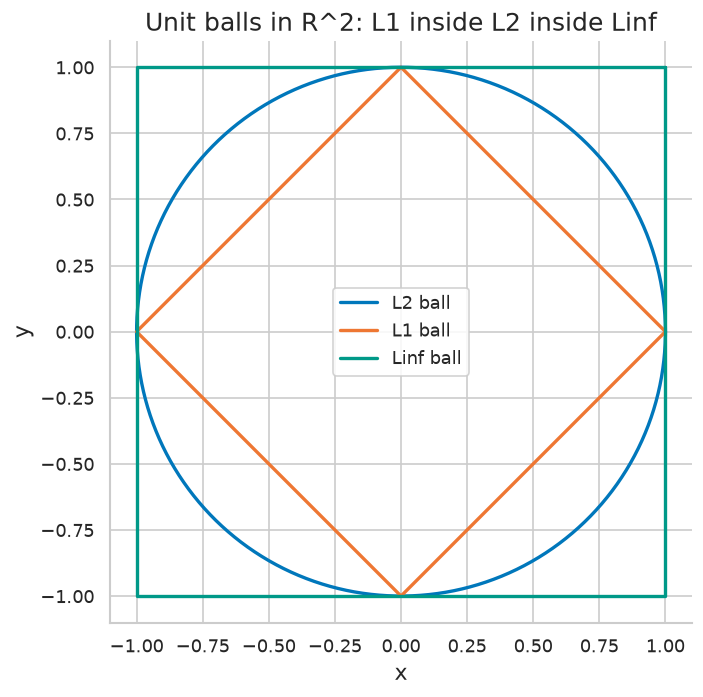

In [22]:

rng = np.random.default_rng(42)
ok = True
for _ in range(500):
    x = rng.normal(size=6)
    n1, n2, ninf = la.norm(x, 1), la.norm(x), la.norm(x, np.inf)
    ok &= (ninf <= n2 + 1e-12) and (n2 <= n1 + 1e-12) and (n2 <= np.sqrt(6) * ninf + 1e-12) and (n1 <= np.sqrt(6) * n2 + 1e-12)
check_true("norm comparisons ||x||inf <= ||x||2 <= ||x||1 <= sqrt(n)||x||2 on 500 draws", ok)
fig, ax = plt.subplots()
th = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(th), np.sin(th), color=WONG[0], label='L2 ball')
ax.plot([1,0,-1,0,1], [0,1,0,-1,0], color=WONG[1], label='L1 ball')
ax.plot([1,1,-1,-1,1], [1,-1,-1,1,1], color=WONG[2], label='Linf ball')
ax.set_title("Unit balls in R^2: L1 inside L2 inside Linf"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

## Appended Demo 11: Cross Products in R^3

The cross product is orthogonal to both factors, and its length is the parallelogram area. Both properties are algebraic identities, checked here directly.

In [23]:

a = np.array([1., 2., 3.]); b = np.array([4., 5., 6.]); c = np.cross(a, b)
check_true("a x b is orthogonal to both factors", abs(c @ a) < 1e-12 and abs(c @ b) < 1e-12)
area = la.norm(c); area_formula = la.norm(a) * la.norm(b) * np.sin(np.arccos((a@b)/(la.norm(a)*la.norm(b))))
check_close("||a x b|| equals the parallelogram area", area, area_formula, 1e-10)
print(f"a x b = {c}; area = {area:.4f}")

PASS: a x b is orthogonal to both factors
PASS: ||a x b|| equals the parallelogram area (max err 7.99e-15, tol 1e-10)
a x b = [-3.  6. -3.]; area = 7.3485


## Appended Demo 12: Linear Versus Affine Versus Convex Combinations

Coefficient sums classify combinations: unrestricted (linear), sum 1 (affine), sum 1 with nonnegative weights (convex). The same points generate a plane, a line, or a segment depending on the rule.

In [24]:

p = np.array([0., 0.]); q = np.array([2., 1.])
mid = 0.5*p + 0.5*q; beyond = -1.0*p + 2.0*q; plane_pt = 3.0*p - 2.0*q
check_close("convex combination lands at the midpoint", mid, np.array([1., 0.5]), 1e-12)
check_true("affine (sum=1) point stays on line pq; linear combo need not", abs(beyond[1] - 0.5*beyond[0]) < 1e-12)
print(f"midpoint {mid} (segment), affine point {beyond} (line), arbitrary combination {plane_pt} (span)")


PASS: convex combination lands at the midpoint (max err 0.00e+00, tol 1e-12)
PASS: affine (sum=1) point stays on line pq; linear combo need not
midpoint [1.  0.5] (segment), affine point [4. 2.] (line), arbitrary combination [-4. -2.] (span)


## Appended Demo 13: Cosine Similarity in High Dimensions

Random high-dimensional vectors are nearly orthogonal: cosine similarities concentrate near zero. This demo measures the concentration that embedding geometry relies on.

In [25]:

rng = np.random.default_rng(42)
X = rng.normal(size=(200, 100)); X = X / la.norm(X, axis=1, keepdims=True)
G = X @ X.T; off = G - np.diag(np.diag(G))
check_true("200 random unit vectors in R^100: all pairwise |cos| < 0.45 (max over ~20k pairs)", np.max(np.abs(off)) < 0.45)
print(f"max |cos| off-diagonal: {np.max(np.abs(off)):.3f}; typical scale 1/sqrt(100) = 0.1")

PASS: 200 random unit vectors in R^100: all pairwise |cos| < 0.45 (max over ~20k pairs)
max |cos| off-diagonal: 0.390; typical scale 1/sqrt(100) = 0.1


## Appended Demo 14: Gram Matrices Are Positive Semidefinite

The Gram matrix G = X X^T packages all pairwise inner products. It must be symmetric positive semidefinite, and Euclidean distances must be recoverable from its entries.

In [26]:

rng = np.random.default_rng(42)
X = rng.normal(size=(8, 5)); G = X @ X.T
evals = la.eigvalsh(G)
check_true("Gram eigenvalues are nonnegative (PSD)", np.min(evals) >= -1e-10)
D2 = np.diag(G)[:, None] + np.diag(G)[None, :] - 2 * G
D_direct = np.sum((X[:, None, :] - X[None, :, :])**2, axis=-1)
check_close("squared distances recovered from the Gram matrix", D2, D_direct, 1e-10)
print(f"smallest Gram eigenvalue: {np.min(evals):.2e} (>= 0 up to rounding)")

PASS: Gram eigenvalues are nonnegative (PSD)
PASS: squared distances recovered from the Gram matrix (max err 1.78e-15, tol 1e-10)
smallest Gram eigenvalue: -4.51e-17 (>= 0 up to rounding)


---
## Key Takeaways

- Vectors are not just arrays. They are elements of spaces with algebra and geometry.
- Basis and dimension tell you how much independent structure a space contains.
- Norms, inner products, and projections are the operational language of optimization and representation.
- High-dimensional geometry explains why random vectors are nearly orthogonal and why random projection works.
- Linear maps are best understood through kernel, image, rank, and nullity.
- Transformers are fundamentally vector-space machines: embeddings, attention, residual streams, and low-rank updates all live in this language.

Suggested next step: go directly to `02-Matrix-Operations/theory.ipynb` and reinterpret matrices as concrete representations of the linear maps studied here.

Useful references for this notebook:
- Axler, *Linear Algebra Done Right* - [https://linear.axler.net/](https://linear.axler.net/)
- Mikolov et al. (2013) - [https://arxiv.org/abs/1301.3781](https://arxiv.org/abs/1301.3781)
- Vaswani et al. (2017) - [https://arxiv.org/abs/1706.03762](https://arxiv.org/abs/1706.03762)
- Ethayarajh (2019) - [https://aclanthology.org/D19-1006/](https://aclanthology.org/D19-1006/)
- Hu et al. (2022) - [https://arxiv.org/abs/2106.09685](https://arxiv.org/abs/2106.09685)
- Jacot et al. (2018) - [https://proceedings.mlr.press/v80/jacot18a.html](https://proceedings.mlr.press/v80/jacot18a.html)
- Miyato et al. (2018) - [https://openreview.net/forum?id=B1QRgziT-](https://openreview.net/forum?id=B1QRgziT-)
- Amari (1998) - [https://papers.nips.cc/paper_files/paper/1998/hash/4b22aa9464f5a138cb5c51cab4093b7b-Abstract.html](https://papers.nips.cc/paper_files/paper/1998/hash/4b22aa9464f5a138cb5c51cab4093b7b-Abstract.html)